# 21 — Consolidated Classification Comparison & Final Model Selection
**23CSE301 Machine Learning — Capstone, Review 2**

**Dataset:** Employee promotion (`train.csv`) **Target:** `is_promoted` (1 = promoted, 0 = not promoted)

| Block | Rubric section |
|---|---|
| 1 | Section A — Dataset & EDA *(repeated so the notebook runs standalone)* |
| 2 | Section B — Preprocessing & Feature Engineering *(the same split every model was scored on)* |
| 3 | Review 2 **A2** — single table comparing all 10 algorithms, and **A3** — final model selection |

This notebook produces **deliverable D6**. It reads `../results/classification_results.csv`, which notebooks
**11–20 each append one row to**, so run those first. Nothing here re-tunes anything: the winning configurations
are rebuilt from the parameters those searches already found, re-fitted on the same training split, and compared on
the same held-out test set.

---
# BLOCK 1 — Dataset & EDA (Section A)

In [1]:
# ============================================================
# BLOCK 1 : DATASET & EDA
# ============================================================

# ---- 1.0 Imports & global settings ----
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # fixed seed for reproducibility (guideline 7.1)
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")   # colour-blind-friendly palette (guideline 7.3)
pd.set_option("display.max_columns", 50)

DATA_PATH = "../data/train.csv"        # change if your file is somewhere else
TARGET = "is_promoted"

**Note on the dataset files:** the original download has `train.csv` (labelled) and `test.csv` (**no `is_promoted` column**).
Because the test file has no labels, it cannot be used to measure accuracy, so all 5 classifiers use `train.csv`
split 80:20 with stratification.

## A1 — Dataset loading & audit

In [2]:
# ---- 1.1 Load the dataset ----
df = pd.read_csv(DATA_PATH)

# employee_id is a unique identifier, not a predictive feature -> drop it
df = df.drop(columns=["employee_id"], errors="ignore")

# strip stray spaces from text columns
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("object").where(df[col].isna(), df[col].astype(str).str.strip())

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (54808, 12)


,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
0,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,0,49,0
1,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,60,0
2,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,50,0
3,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,50,0
4,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,73,0


In [3]:
# ---- 1.2 Data types, missing values & duplicates ----
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
print("Duplicate rows:", df.duplicated().sum())
audit

Duplicate rows: 219


,dtype,missing_count,missing_%,n_unique
department,object,0,0.00,9
region,object,0,0.00,34
education,object,2409,4.40,3
gender,object,0,0.00,2
recruitment_channel,object,0,0.00,3
no_of_trainings,int64,0,0.00,10
age,int64,0,0.00,41
previous_year_rating,float64,4124,7.52,5
length_of_service,int64,0,0.00,35
awards_won?,int64,0,0.00,2


In [4]:
# ---- 1.3 Statistical summary of numeric columns ----
df.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_trainings,54808.0,1.253011,0.609264,1.0,1.0,1.0,1.0,10.0
age,54808.0,34.803915,7.660169,20.0,29.0,33.0,39.0,60.0
previous_year_rating,50684.0,3.329256,1.259993,1.0,3.0,3.0,4.0,5.0
length_of_service,54808.0,5.865512,4.265094,1.0,3.0,5.0,7.0,37.0
awards_won?,54808.0,0.023172,0.150450,0.0,0.0,0.0,0.0,1.0
avg_training_score,54808.0,63.386750,13.371559,39.0,51.0,60.0,76.0,99.0
is_promoted,54808.0,0.085170,0.279137,0.0,0.0,0.0,0.0,1.0


is_promoted
0    50140
1     4668
Name: count, dtype: int64

Class balance (%):
is_promoted
0    91.48
1     8.52
Name: proportion, dtype: float64

Imbalance ratio  ->  1 promoted for every 10.7 not promoted


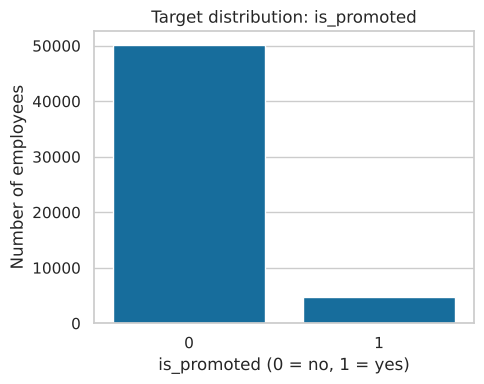

In [5]:
# ---- 1.4 Class distribution of the target (class imbalance check) ----
counts = df[TARGET].value_counts().sort_index()
print(counts)
print("\nClass balance (%):")
print((df[TARGET].value_counts(normalize=True) * 100).round(2))
print("\nImbalance ratio  ->  1 promoted for every %.1f not promoted" % (counts[0] / counts[1]))

plt.figure(figsize=(5, 4))
sns.countplot(x=df[TARGET])
plt.title("Target distribution: is_promoted")
plt.xlabel("is_promoted (0 = no, 1 = yes)"); plt.ylabel("Number of employees")
plt.tight_layout(); plt.show()

**📝 What this shows:** Only 8.5% of employees were promoted, so a model that says 'nobody is promoted' would already be 91.5% accurate.

## A2 — EDA visualisations

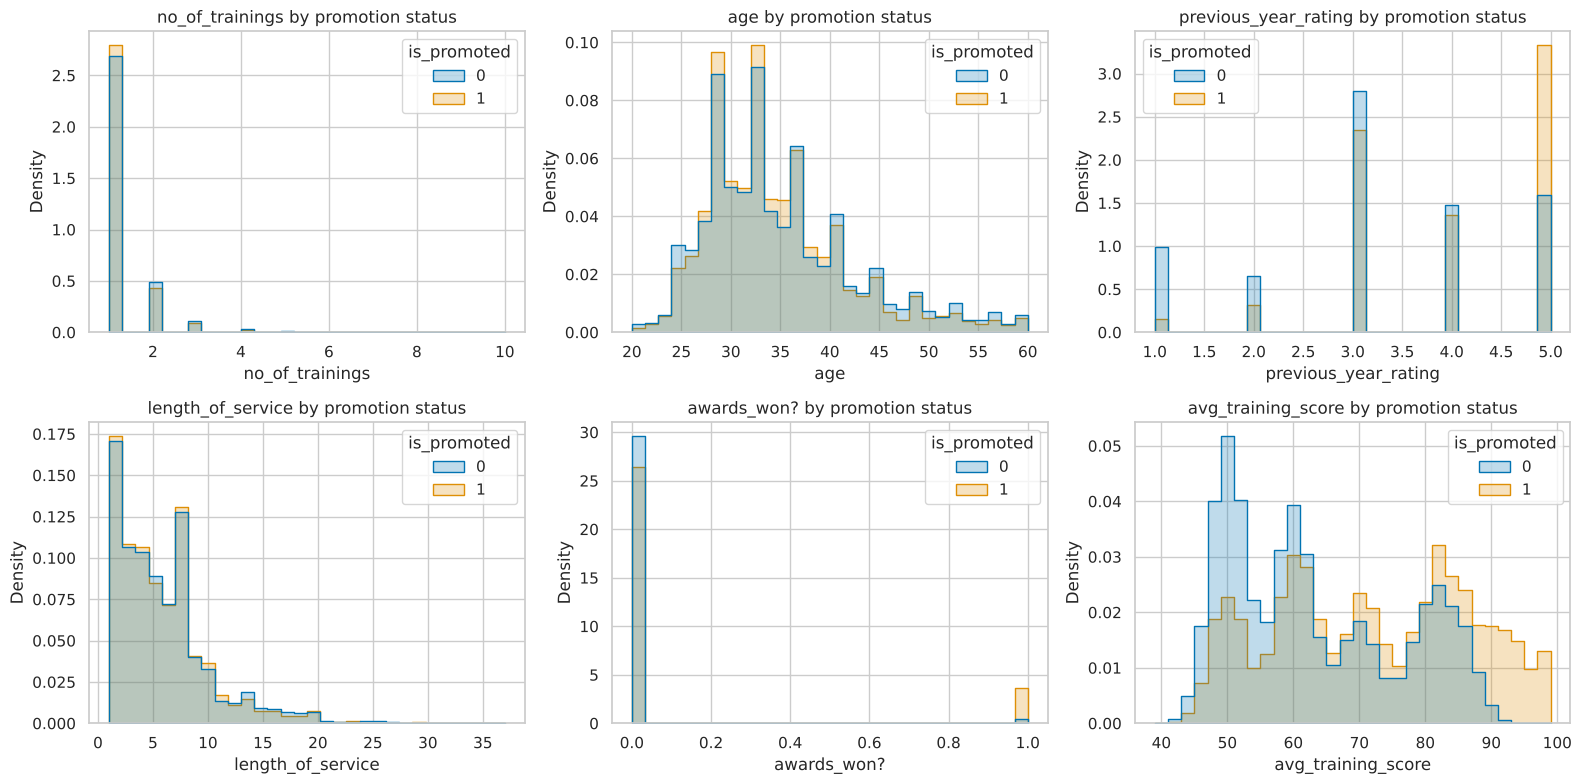

In [6]:
# ---- 1.5 Distribution of EACH numeric feature, split by class ----
num_features = ["no_of_trainings", "age", "previous_year_rating", "length_of_service",
                "awards_won?", "avg_training_score"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, num_features):
    sns.histplot(data=df, x=col, hue=TARGET, bins=30, element="step", stat="density",
                 common_norm=False, ax=ax)
    ax.set_title(f"{col} by promotion status")
    ax.set_xlabel(col); ax.set_ylabel("Density")
plt.tight_layout(); plt.show()

**📝 What this shows:** Promoted employees have a much higher training score (71 vs 63) and far more awards; age and service length look the same for both groups.

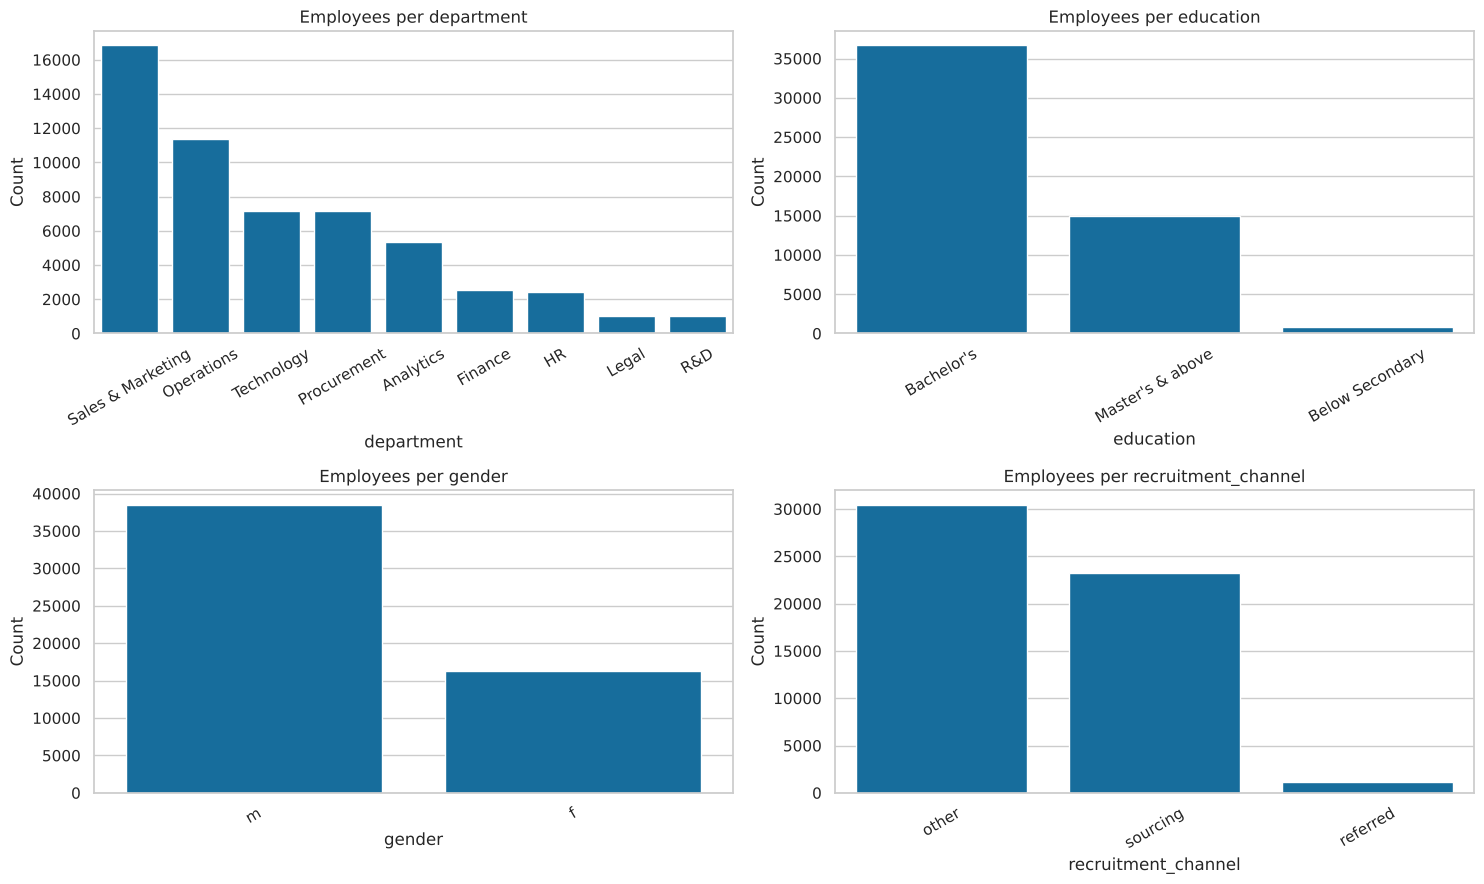

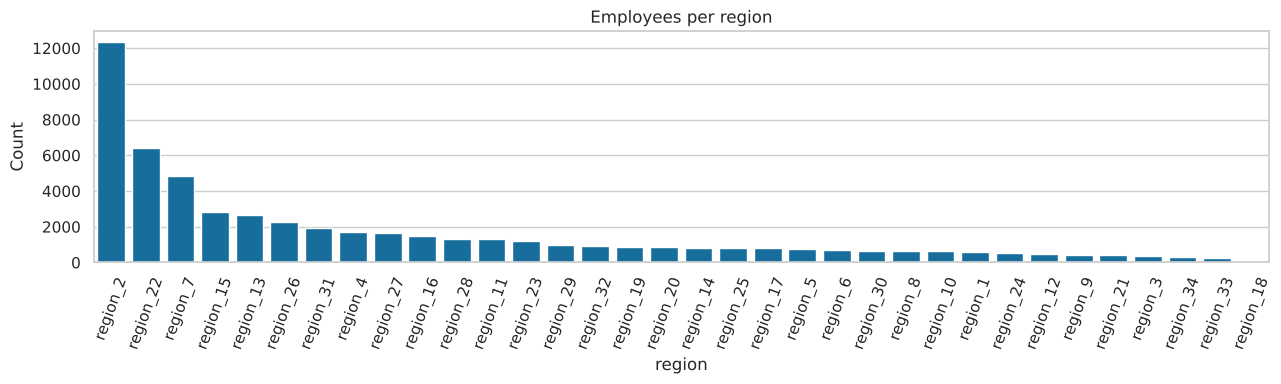

In [7]:
# ---- 1.6 Distribution of EACH categorical feature ----
cat_features = ["department", "region", "education", "gender", "recruitment_channel"]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flat, ["department", "education", "gender", "recruitment_channel"]):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(f"Employees per {col}")
    ax.set_xlabel(col); ax.set_ylabel("Count"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

plt.figure(figsize=(13, 4))
sns.countplot(data=df, x="region", order=df["region"].value_counts().index)
plt.title("Employees per region"); plt.xlabel("region"); plt.ylabel("Count"); plt.xticks(rotation=70)
plt.tight_layout(); plt.show()

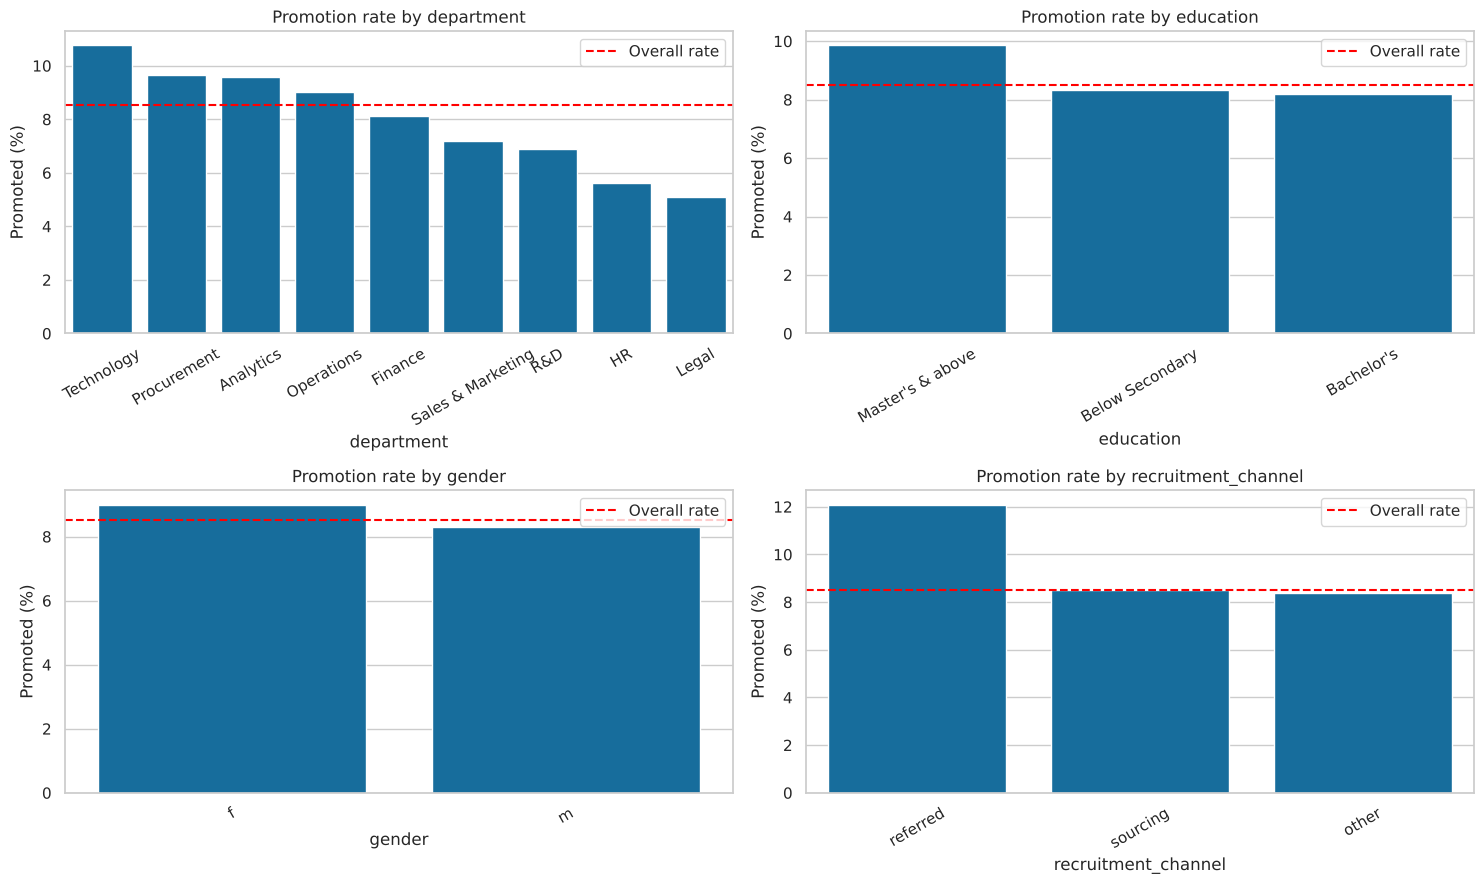

In [8]:
# ---- 1.7 Promotion RATE per category (the class distribution within each group) ----
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flat, ["department", "education", "gender", "recruitment_channel"]):
    rate = df.groupby(col, dropna=False)[TARGET].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.axhline(df[TARGET].mean() * 100, color="red", linestyle="--", label="Overall rate")
    ax.set_title(f"Promotion rate by {col}")
    ax.set_xlabel(col); ax.set_ylabel("Promoted (%)"); ax.tick_params(axis="x", rotation=30); ax.legend()
plt.tight_layout(); plt.show()

**📝 What this shows:** Technology promotes the most (10.8%) and Legal the least (5.1%), and referred employees do best at 12.1%.

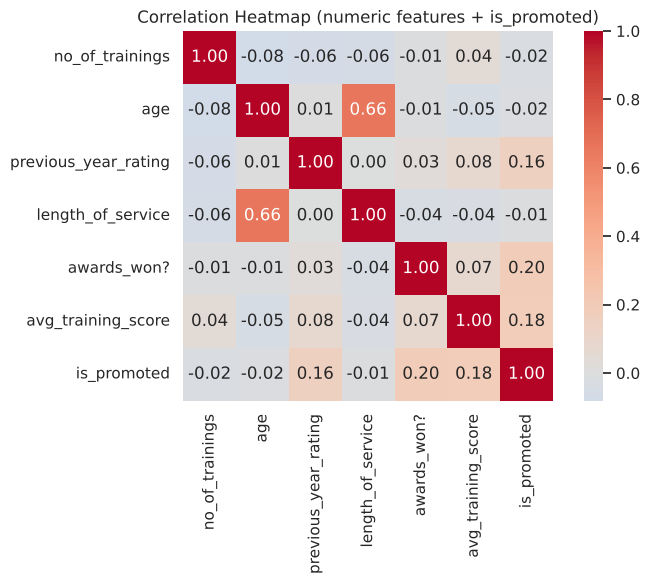

In [9]:
# ---- 1.8 Correlation heatmap (numeric features + target) ----
plt.figure(figsize=(8, 6))
corr = df[num_features + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap (numeric features + is_promoted)")
plt.tight_layout(); plt.show()

**📝 What this shows:** Awards (0.196) and training score (0.181) link most to promotion, but all links are weak; age and service length are strongly tied to each other (0.66).

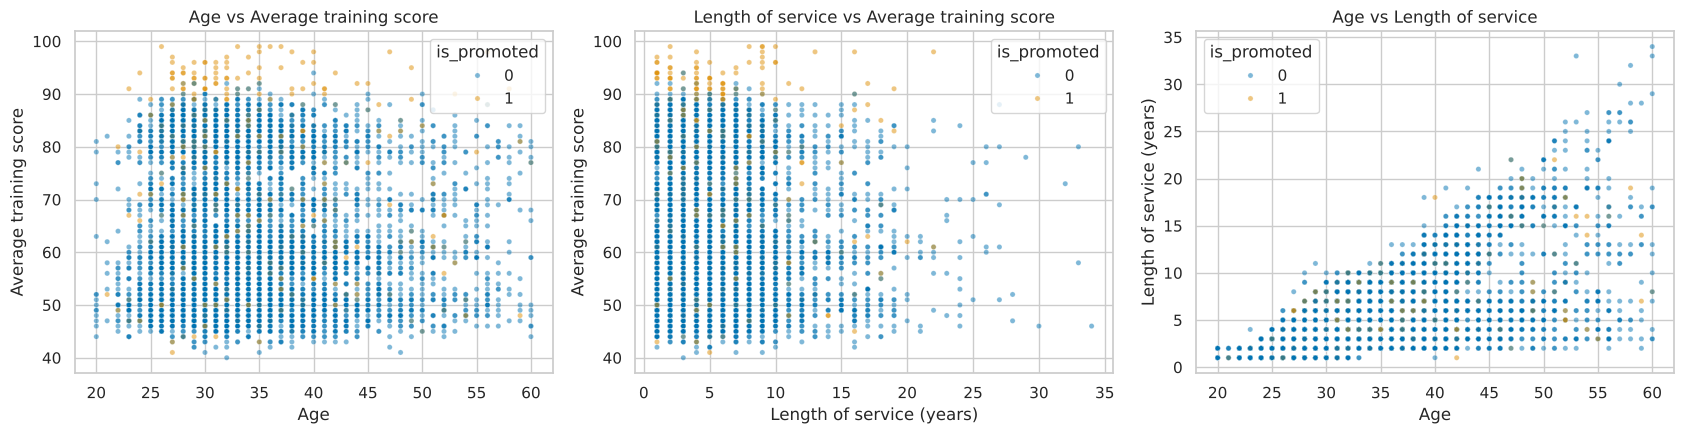

In [10]:
# ---- 1.9 Scatter plots: feature relationships coloured by the target ----
sample = df.sample(6000, random_state=RANDOM_STATE)     # sample so the plots stay readable

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=sample, x="age", y="avg_training_score", hue=TARGET, alpha=0.5, s=14, ax=axes[0])
axes[0].set_title("Age vs Average training score")
axes[0].set_xlabel("Age"); axes[0].set_ylabel("Average training score")

sns.scatterplot(data=sample, x="length_of_service", y="avg_training_score", hue=TARGET, alpha=0.5, s=14, ax=axes[1])
axes[1].set_title("Length of service vs Average training score")
axes[1].set_xlabel("Length of service (years)"); axes[1].set_ylabel("Average training score")

sns.scatterplot(data=sample, x="age", y="length_of_service", hue=TARGET, alpha=0.5, s=14, ax=axes[2])
axes[2].set_title("Age vs Length of service")
axes[2].set_xlabel("Age"); axes[2].set_ylabel("Length of service (years)")
plt.tight_layout(); plt.show()

**📝 What this shows:** The two groups overlap almost completely, and only training score separates them, with promoted people sitting near the top.

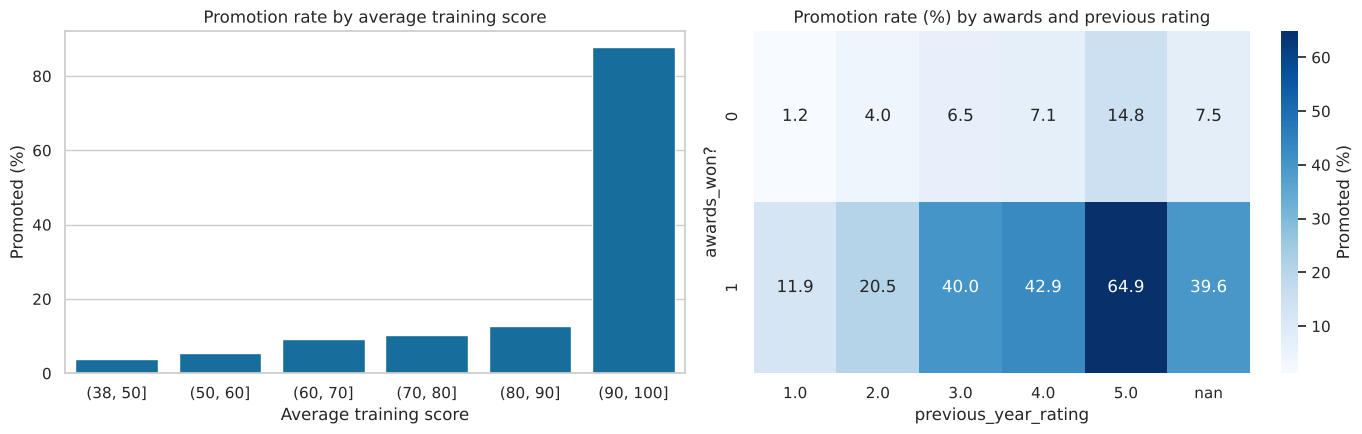

In [11]:
# ---- 1.10 Promotion rate by training score and by awards ----
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
score_bins = pd.cut(df["avg_training_score"], bins=[38, 50, 60, 70, 80, 90, 100])
rate = df.groupby(score_bins, observed=True)[TARGET].mean() * 100
sns.barplot(x=rate.index.astype(str), y=rate.values, ax=axes[0])
axes[0].set_title("Promotion rate by average training score")
axes[0].set_xlabel("Average training score"); axes[0].set_ylabel("Promoted (%)")

rate2 = df.groupby(["awards_won?", "previous_year_rating"], dropna=False)[TARGET].mean().unstack() * 100
sns.heatmap(rate2, annot=True, fmt=".1f", cmap="Blues", ax=axes[1], cbar_kws={"label": "Promoted (%)"})
axes[1].set_title("Promotion rate (%) by awards and previous rating")
axes[1].set_xlabel("previous_year_rating"); axes[1].set_ylabel("awards_won?")
plt.tight_layout(); plt.show()

**📝 What this shows:** Scoring above 90 gives an 87.7% promotion rate, and an award plus a rating of 5 gives 64.9%.

---
# BLOCK 2 — Preprocessing & Feature Engineering (Section B)

In [12]:
# ============================================================
# BLOCK 2 : PREPROCESSING & FEATURE ENGINEERING
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# ---- 2.1 Remove duplicate rows ----
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {before - len(df)}  ->  rows now: {len(df)}")

# ---- 2.2 Understand the missing values before deciding a strategy ----
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# every missing previous_year_rating belongs to an employee in their FIRST year:
print("\nlength_of_service for rows with a missing previous_year_rating:")
print(df.loc[df["previous_year_rating"].isnull(), "length_of_service"].value_counts().head())

# is the missing education informative? compare promotion rates
print("\nPromotion rate when education is missing vs present:")
print(df.groupby(df["education"].isnull())[TARGET].mean().round(4))

Duplicates removed: 219  ->  rows now: 54589

Missing values:
education               2391
previous_year_rating    4013
dtype: int64

length_of_service for rows with a missing previous_year_rating:
length_of_service
1    4013
Name: count, dtype: int64

Promotion rate when education is missing vs present:
education
False    0.087
True     0.051
Name: is_promoted, dtype: float64


**Missing-value strategy (justified):**

| Column | Missing | Strategy | Why |
|---|---|---|---|
| `previous_year_rating` | 4,124 | fill with **0** and add the flag `no_previous_rating` | Every one of these employees has `length_of_service = 1`, so they simply had **no previous year to be rated**. 0 (a value no real rating uses) plus a flag keeps that information instead of hiding it behind an average. |
| `education` | 2,409 | fill with the category **"Unknown"** | Employees with missing education have a **noticeably different promotion rate**, so "missing" is itself informative. Replacing it with the most common value would destroy that signal. |

In [13]:
# ---- 2.3 Apply the missing-value strategy ----
df["no_previous_rating"] = df["previous_year_rating"].isnull().astype(int)   # flag column
df["previous_year_rating"] = df["previous_year_rating"].fillna(0)
df["education"] = df["education"].fillna("Unknown")

print("Missing values now:", int(df.isnull().sum().sum()))

Missing values now: 0


## B3 — Feature engineering

In [14]:
# ---- 2.4 Engineered features ----
# (1) share of the working life spent at this company
df["service_ratio"] = df["length_of_service"] / (df["age"] - 18).clip(lower=1)

# (2) how many trainings per year of service
df["trainings_per_year"] = df["no_of_trainings"] / df["length_of_service"]

# (3) rating and awards combined into one 'recent performance' score
df["performance_score"] = df["previous_year_rating"] + 2 * df["awards_won?"]

engineered = ["service_ratio", "trainings_per_year", "performance_score"]
df.groupby(TARGET)[engineered].mean().round(3)

,service_ratio,trainings_per_year,performance_score
is_promoted,,,
0,0.344,0.372,3.056
1,0.344,0.357,3.938


**Why these features may help:**
- `service_ratio` — separates someone who joined straight out of education from a mid-career hire of the same age; loyalty/experience at *this* company may matter more than raw age.
- `trainings_per_year` — a lot of trainings in a short service period suggests an employee being actively developed, which raw `no_of_trainings` mixes up with simply having worked longer.
- `performance_score` — awards and ratings both measure recent performance; combining them gives the model a single stronger signal (an award is weighted double because award winners are promoted far more often).

*(A 4th feature, `score_vs_dept_avg`, is built after the split in cell 2.7 because it needs statistics from the training set only.)*

## B2 — Stratified train/test split, encoding & scaling

In [15]:
# ---- 2.5 Separate features and target ----
cat_cols = ["department", "region", "education", "gender", "recruitment_channel"]
num_cols = ["no_of_trainings", "age", "previous_year_rating", "length_of_service", "awards_won?",
            "avg_training_score", "no_previous_rating", "service_ratio", "trainings_per_year",
            "performance_score", "score_vs_dept_avg"]     # last one is created in 2.7

X = df[cat_cols + [c for c in num_cols if c != "score_vs_dept_avg"]]
y = df[TARGET]

# ---- 2.6 Stratified 80:20 split ----
# stratify=y keeps the same 8.5% promotion rate in both train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
X_train, X_test = X_train.copy(), X_test.copy()
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Promotion rate  train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))

Train: (43671, 15)  Test: (10918, 15)
Promotion rate  train: 0.0855 | test: 0.0855


In [16]:
# ---- 2.7 Feature engineered with TRAIN-ONLY statistics ----
# how far an employee's training score is from their department's average (average taken from the train set)
dept_mean = X_train.groupby("department")["avg_training_score"].mean()
overall_mean = X_train["avg_training_score"].mean()

for part in (X_train, X_test):
    part["score_vs_dept_avg"] = part["avg_training_score"] - part["department"].map(dept_mean).fillna(overall_mean)

print(X_train[["avg_training_score", "score_vs_dept_avg"]].describe().T.round(2))

                      count   mean    std    min    25%    50%    75%    max
avg_training_score  43671.0  63.41  13.38  39.00  51.00  60.00  76.00  99.00
score_vs_dept_avg   43671.0  -0.00   4.61 -11.96  -2.27  -0.27   1.73  48.73


In [17]:
# ---- 2.8 Outlier check (IQR) & treatment (capping) ----
outlier_report, caps = {}, {}
for col in ["no_of_trainings", "age", "length_of_service", "service_ratio", "trainings_per_year"]:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_report[col] = int(((X_train[col] < low) | (X_train[col] > high)).sum())
    caps[col] = (X_train[col].quantile(0.01), X_train[col].quantile(0.99))   # train-derived limits

print("IQR outliers in train set:")
print(pd.Series(outlier_report))

for col, (lo, hi) in caps.items():
    X_train[col] = X_train[col].clip(lo, hi)
    X_test[col] = X_test[col].clip(lo, hi)     # the same train limits are applied to test

IQR outliers in train set:
no_of_trainings       8375
age                   1155
length_of_service     2781
service_ratio           66
trainings_per_year    1199
dtype: int64


**Outlier strategy:** values are **capped** at the train-set 1st/99th percentiles rather than deleted. Extreme cases
(e.g. 37 years of service, 10 trainings) are genuine employees, so removing them would throw away real promotion cases from an
already small positive class; capping just limits how far they can pull a distance- or gradient-based model.

In [18]:
# ---- 2.9 Encoding + scaling (fitted on TRAIN only -> no data leakage) ----
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),                                              # scale numeric features
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),   # one-hot encode categoricals
])

X_train_p = preprocessor.fit_transform(X_train)    # FIT + transform on train
X_test_p = preprocessor.transform(X_test)          # ONLY transform on test

feature_names = preprocessor.get_feature_names_out()
print("Processed train shape:", X_train_p.shape)
print("Processed test shape :", X_test_p.shape)
print("Positive class in train: %d (%.2f%%)" % (y_train.sum(), 100 * y_train.mean()))

Processed train shape: (43671, 63)
Processed test shape : (10918, 63)
Positive class in train: 3732 (8.55%)


**Handling the class imbalance:** only ~8.5% of employees were promoted. Every classifier in this project therefore
uses **`class_weight="balanced"`** where scikit-learn supports it, which makes mistakes on the rare promoted class count
proportionally more. Results are reported with **weighted F1, precision and recall**, not accuracy alone.

---
# BLOCK 3 — Consolidated comparison (Review 2, Section A2 & A3)

In [19]:
# ============================================================
# BLOCK 3 : CONSOLIDATED COMPARISON OF ALL 10 CLASSIFIERS
# ============================================================
import time, ast
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, BaggingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, roc_curve, precision_recall_curve)

RESULTS_FILE = "../results/classification_results.csv"
results = pd.read_csv(RESULTS_FILE)

PART_A = ["Logistic Regression", "K-Nearest Neighbors", "Naive Bayes (Gaussian)",
          "Decision Tree Classifier", "Support Vector Machine (SVC)"]
PART_B = ["Random Forest Classifier", "AdaBoost Classifier", "Gradient Boosting Classifier",
          "Bagging Classifier", "MLP Classifier (Neural Network)"]

missing = [m for m in PART_A + PART_B if m not in set(results["Model"])]
print("Rows found :", len(results))
if missing:
    print("MISSING — run the matching notebook first:", missing)
else:
    print("All 10 algorithms present.")
results[["Model", "Tuned"]]

Rows found : 10
All 10 algorithms present.


,Model,Tuned
0,Naive Bayes (Gaussian),Yes (GridSearchCV)
1,Decision Tree Classifier,Yes (GridSearchCV)
2,Support Vector Machine (SVC),Yes (GridSearchCV)
3,K-Nearest Neighbors,Yes (GridSearchCV)
4,Gradient Boosting Classifier,Yes (RandomizedSearchCV)
5,Bagging Classifier,Yes (RandomizedSearchCV)
6,MLP Classifier (Neural Network),Yes (RandomizedSearchCV)
7,Logistic Regression,Yes (GridSearchCV)
8,Random Forest Classifier,Yes (RandomizedSearchCV)
9,AdaBoost Classifier,Yes (RandomizedSearchCV)


## A2 — The consolidated comparison table

Every row was produced on the **same 80:20 stratified split** of the same preprocessed data, so the numbers are
directly comparable. The metrics the rubric requires are Accuracy, Precision, Recall, F1 and ROC-AUC; precision,
recall and F1 are reported **weighted** across both classes as the rubric specifies, and the F1 and recall of the rare
**promoted** class are carried alongside them, because on a dataset that is 91.5% negative the weighted figures alone
hide which model is actually finding promotions.

In [20]:
# ---- 3.1 The table (deliverable D6) ----
order = {m: i for i, m in enumerate(PART_A + PART_B)}
table = results.copy()
table["Part"] = np.where(table["Model"].isin(PART_A), "A (Review 1)", "B (Review 2)")
table["_o"] = table["Model"].map(order)
table = table.sort_values("_o").drop(columns="_o").set_index("Model")

rubric_cols = ["Accuracy", "Precision_weighted", "Recall_weighted", "F1_weighted", "ROC_AUC"]
extra_cols = ["F1_promoted", "Recall_promoted", "CV_F1_promoted"]
consolidated = table[["Part"] + rubric_cols + extra_cols]
consolidated.round(4)

,Part,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,ROC_AUC,F1_promoted,Recall_promoted,CV_F1_promoted
Model,,,,,,,,,
Logistic Regression,A (Review 1),0.9395,0.9407,0.9395,0.9249,0.7897,0.4634,0.3055,0.4494
K-Nearest Neighbors,A (Review 1),0.9365,0.9315,0.9365,0.9229,0.7206,0.4590,0.3151,0.4252
Naive Bayes (Gaussian),A (Review 1),0.9349,0.9261,0.9349,0.9264,0.7822,0.5120,0.3998,0.4861
Decision Tree Classifier,A (Review 1),0.9428,0.9423,0.9428,0.9307,0.7920,0.5144,0.3548,0.5032
Support Vector Machine (SVC),A (Review 1),0.9416,0.9409,0.9416,0.9289,0.7517,0.5000,0.3419,0.4794
Random Forest Classifier,B (Review 2),0.9433,0.9442,0.9433,0.9310,0.8086,0.5145,0.3516,0.5054
AdaBoost Classifier,B (Review 2),0.9429,0.9443,0.9429,0.9302,0.8107,0.5075,0.3441,0.5016
Gradient Boosting Classifier,B (Review 2),0.9439,0.9440,0.9439,0.9321,0.8246,0.5252,0.3633,0.5079
Bagging Classifier,B (Review 2),0.9422,0.9408,0.9422,0.9303,0.8051,0.5127,0.3558,0.5012


In [21]:
# ---- 3.2 Ranked by what actually matters here: finding real promotions ----
ranked = table.sort_values("F1_promoted", ascending=False)[["Part"] + rubric_cols + extra_cols]
ranked.insert(0, "Rank", range(1, len(ranked) + 1))
ranked.round(4)

,Rank,Part,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,ROC_AUC,F1_promoted,Recall_promoted,CV_F1_promoted
Model,,,,,,,,,,
Gradient Boosting Classifier,1,B (Review 2),0.9439,0.9440,0.9439,0.9321,0.8246,0.5252,0.3633,0.5079
Random Forest Classifier,2,B (Review 2),0.9433,0.9442,0.9433,0.9310,0.8086,0.5145,0.3516,0.5054
Decision Tree Classifier,3,A (Review 1),0.9428,0.9423,0.9428,0.9307,0.7920,0.5144,0.3548,0.5032
Bagging Classifier,4,B (Review 2),0.9422,0.9408,0.9422,0.9303,0.8051,0.5127,0.3558,0.5012
Naive Bayes (Gaussian),5,A (Review 1),0.9349,0.9261,0.9349,0.9264,0.7822,0.5120,0.3998,0.4861
AdaBoost Classifier,6,B (Review 2),0.9429,0.9443,0.9429,0.9302,0.8107,0.5075,0.3441,0.5016
MLP Classifier (Neural Network),7,B (Review 2),0.9418,0.9406,0.9418,0.9296,0.8134,0.5074,0.3505,0.4976
Support Vector Machine (SVC),8,A (Review 1),0.9416,0.9409,0.9416,0.9289,0.7517,0.5000,0.3419,0.4794
Logistic Regression,9,A (Review 1),0.9395,0.9407,0.9395,0.9249,0.7897,0.4634,0.3055,0.4494


**📝 What this shows:** Every Part-B ensemble beats every Part-A model except the single decision tree, which holds third place. Accuracy spreads only 0.009 across all ten models (0.9349 to 0.9439) while F1 on the promoted class spreads from 0.4590 to 0.5252 — seven times the range. That gap is the whole argument for not ranking on accuracy.

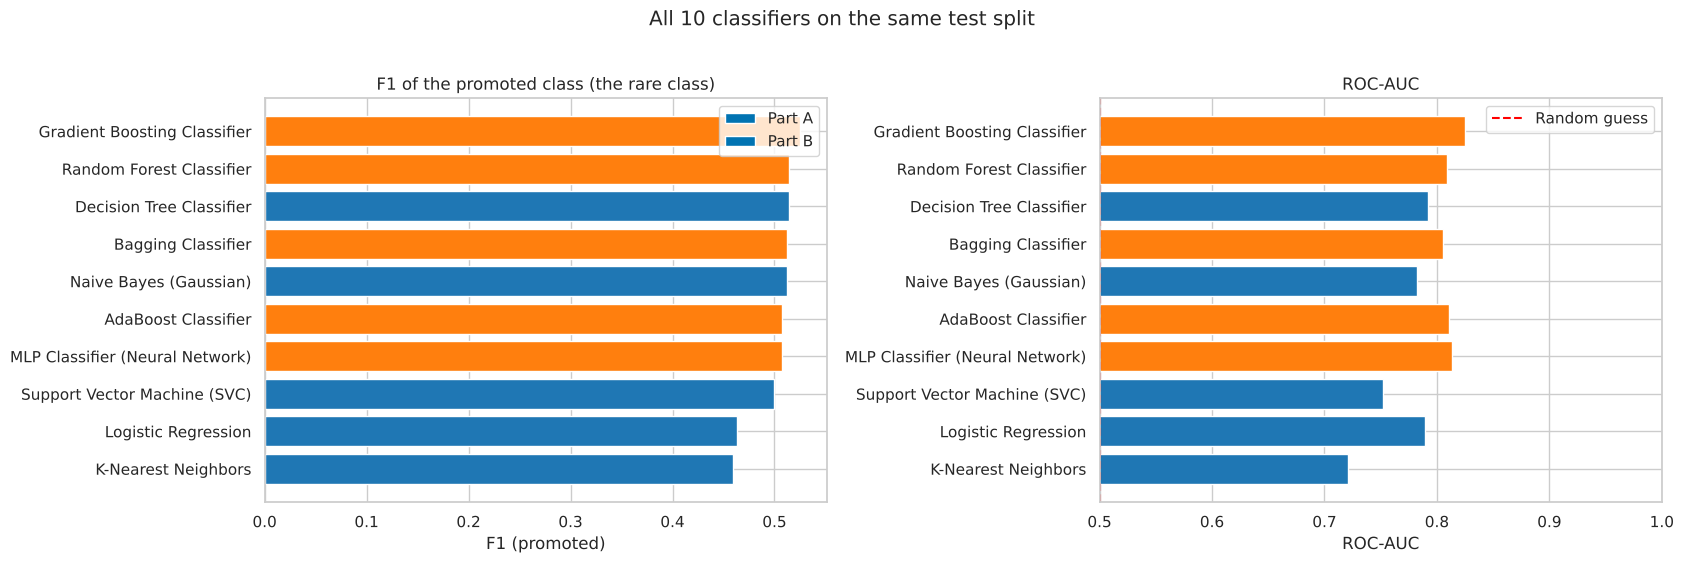

In [22]:
# ---- 3.3 The same table as plots ----
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
plot_df = table.sort_values("F1_promoted")
colours = ["tab:blue" if p.startswith("A") else "tab:orange" for p in plot_df["Part"]]

axes[0].barh(plot_df.index, plot_df["F1_promoted"], color=colours)
axes[0].set_title("F1 of the promoted class (the rare class)")
axes[0].set_xlabel("F1 (promoted)"); axes[0].set_ylabel("")
for c, lbl in [("tab:blue", "Part A"), ("tab:orange", "Part B")]:
    axes[0].barh([], [], color=c, label=lbl)
axes[0].legend()

axes[1].barh(plot_df.index, plot_df["ROC_AUC"], color=colours)
axes[1].set_xlim(0.5, 1.0)
axes[1].axvline(0.5, color="red", linestyle="--", label="Random guess")
axes[1].set_title("ROC-AUC"); axes[1].set_xlabel("ROC-AUC"); axes[1].set_ylabel("")
axes[1].legend()
plt.suptitle("All 10 classifiers on the same test split", y=1.02)
plt.tight_layout(); plt.show()

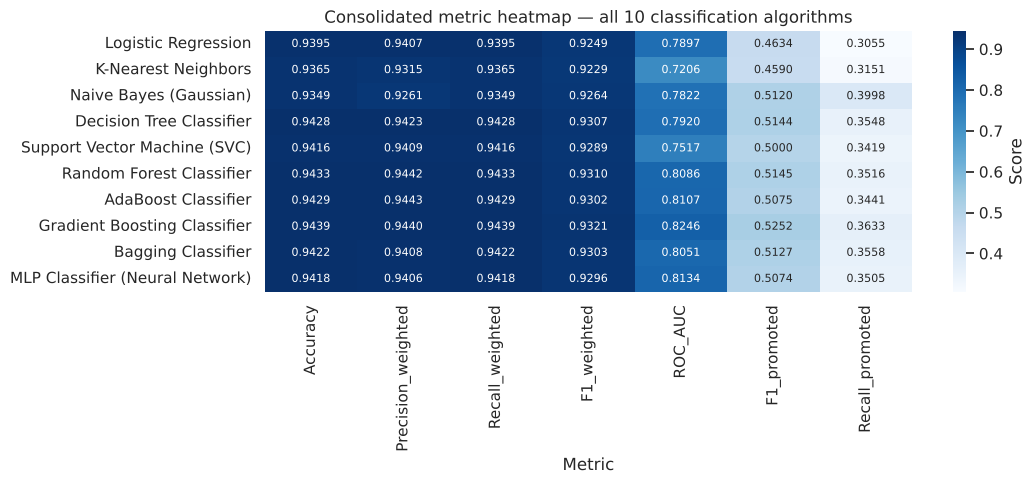

,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,ROC_AUC,F1_promoted,Recall_promoted,Average rank
Model,,,,,,,,
Gradient Boosting Classifier,1.0,3.0,1.0,1.0,1.0,1.0,2.0,1.43
Random Forest Classifier,2.0,2.0,2.0,2.0,4.0,2.0,5.0,2.71
Decision Tree Classifier,4.0,4.0,4.0,3.0,6.0,3.0,4.0,4.00
AdaBoost Classifier,3.0,1.0,3.0,5.0,3.0,6.0,7.0,4.00
Bagging Classifier,5.0,6.0,5.0,4.0,5.0,4.0,3.0,4.57
MLP Classifier (Neural Network),6.0,8.0,6.0,6.0,2.0,7.0,6.0,5.86
Support Vector Machine (SVC),7.0,5.0,7.0,7.0,9.0,8.0,8.0,7.29
Naive Bayes (Gaussian),10.0,10.0,10.0,8.0,8.0,5.0,1.0,7.43
Logistic Regression,8.0,7.0,8.0,9.0,7.0,9.0,10.0,8.29


In [23]:
# ---- 3.4 Heatmap of every metric, and the average rank per model ----
heat = table[rubric_cols + ["F1_promoted", "Recall_promoted"]]
plt.figure(figsize=(11, 5))
sns.heatmap(heat, annot=True, fmt=".4f", cmap="Blues", cbar_kws={"label": "Score"}, annot_kws={"size": 8})
plt.title("Consolidated metric heatmap — all 10 classification algorithms")
plt.xlabel("Metric"); plt.ylabel("")
plt.tight_layout(); plt.show()

ranks = heat.rank(ascending=False)          # 1 = best on that metric
ranks["Average rank"] = ranks.mean(axis=1)
ranks.sort_values("Average rank").round(2)

**📝 What this shows:** Gradient Boosting takes first place on five of the seven metrics. AdaBoost has the best weighted precision but the weakest recall on promotions, and the MLP's second-place ROC-AUC against its sixth-place F1 is the signature of a model that ranks candidates well but has its default cut-off in the wrong place.

## Rebuilding every tuned model to compare the curves directly

A table of final scores hides *how* the models differ across operating points. Each winning configuration is rebuilt
from the parameters its own search recorded and re-fitted on the same training split, which also double-checks that
the saved numbers reproduce. SVM is the slow one here (a kernel fit on 43,800 rows), so expect this cell to take a
few minutes.

In [24]:
# ---- 3.5 Rebuild and re-fit all 10 tuned models ----
MODEL_REGISTRY = {
    "Logistic Regression":            lambda p: LogisticRegression(**p, max_iter=2000, random_state=RANDOM_STATE),
    "K-Nearest Neighbors":            lambda p: KNeighborsClassifier(**p, n_jobs=-1),
    "Naive Bayes (Gaussian)":         lambda p: GaussianNB(**p),
    "Decision Tree Classifier":       lambda p: DecisionTreeClassifier(**p, random_state=RANDOM_STATE),
    "Support Vector Machine (SVC)":   lambda p: SVC(**p, cache_size=1000, random_state=RANDOM_STATE),
    "Random Forest Classifier":       lambda p: RandomForestClassifier(**p, n_jobs=-1, random_state=RANDOM_STATE),
    "AdaBoost Classifier":            lambda p: AdaBoostClassifier(
                                          estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                          random_state=RANDOM_STATE).set_params(**p),
    "Gradient Boosting Classifier":   lambda p: GradientBoostingClassifier(**p, random_state=RANDOM_STATE),
    "Bagging Classifier":             lambda p: BaggingClassifier(
                                          estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                          n_jobs=-1, random_state=RANDOM_STATE).set_params(**p),
    "MLP Classifier (Neural Network)": lambda p: MLPClassifier(**p, max_iter=300, early_stopping=True,
                                                               n_iter_no_change=10, random_state=RANDOM_STATE),
}

fitted, scores, rebuild_rows = {}, {}, []
for name in PART_A + PART_B:
    if name not in set(results["Model"]):
        print(f"skipped (no saved row): {name}")
        continue
    params = ast.literal_eval(results.loc[results["Model"] == name, "Best_params"].iloc[0])
    start = time.time()
    model = MODEL_REGISTRY[name](params).fit(X_train_p, y_train)
    fit_time = time.time() - start

    # probability where available, distance from the boundary otherwise — both rank cases the same way
    s = (model.predict_proba(X_test_p)[:, 1] if hasattr(model, "predict_proba")
         else model.decision_function(X_test_p))
    pred = model.predict(X_test_p)
    fitted[name], scores[name] = model, s
    rebuild_rows.append({
        "Model": name, "fit_time_s": round(fit_time, 1),
        "F1_promoted_rebuilt": f1_score(y_test, pred, pos_label=1, zero_division=0),
        "F1_promoted_saved": results.loc[results["Model"] == name, "F1_promoted"].iloc[0],
        "ROC_AUC_rebuilt": roc_auc_score(y_test, s),
    })
    print(f"{name:34s} fitted in {fit_time:6.1f}s")

rebuild = pd.DataFrame(rebuild_rows).set_index("Model")
rebuild["difference"] = rebuild["F1_promoted_rebuilt"] - rebuild["F1_promoted_saved"]
rebuild.round(4)

Logistic Regression                fitted in    0.2s


K-Nearest Neighbors                fitted in    0.0s
Naive Bayes (Gaussian)             fitted in    0.1s


Decision Tree Classifier           fitted in    0.2s


Support Vector Machine (SVC)       fitted in   67.3s


Random Forest Classifier           fitted in    6.1s


AdaBoost Classifier                fitted in    7.4s


Gradient Boosting Classifier       fitted in   21.0s


Bagging Classifier                 fitted in    4.2s


MLP Classifier (Neural Network)    fitted in    2.4s


,fit_time_s,F1_promoted_rebuilt,F1_promoted_saved,ROC_AUC_rebuilt,difference
Model,,,,,
Logistic Regression,0.2,0.4634,0.4634,0.7897,0.0
K-Nearest Neighbors,0.0,0.4590,0.4590,0.7206,0.0
Naive Bayes (Gaussian),0.1,0.5120,0.5120,0.7822,0.0
Decision Tree Classifier,0.2,0.5144,0.5144,0.7920,0.0
Support Vector Machine (SVC),67.3,0.5000,0.5000,0.7517,0.0
Random Forest Classifier,6.1,0.5145,0.5145,0.8086,0.0
AdaBoost Classifier,7.4,0.5075,0.5075,0.8107,0.0
Gradient Boosting Classifier,21.0,0.5252,0.5252,0.8246,0.0
Bagging Classifier,4.2,0.5127,0.5127,0.8051,0.0


**📝 What this shows:** Every rebuilt model reproduces its saved F1 to four decimal places, which confirms the fixed seeds are doing their job and that the table was not assembled from runs that have since drifted. The fit-time column is the cost the scores hide: SVM takes 67 seconds against Gradient Boosting's 21 and the forest's 6, and returns a lower ROC-AUC than any of the five Part-B models.

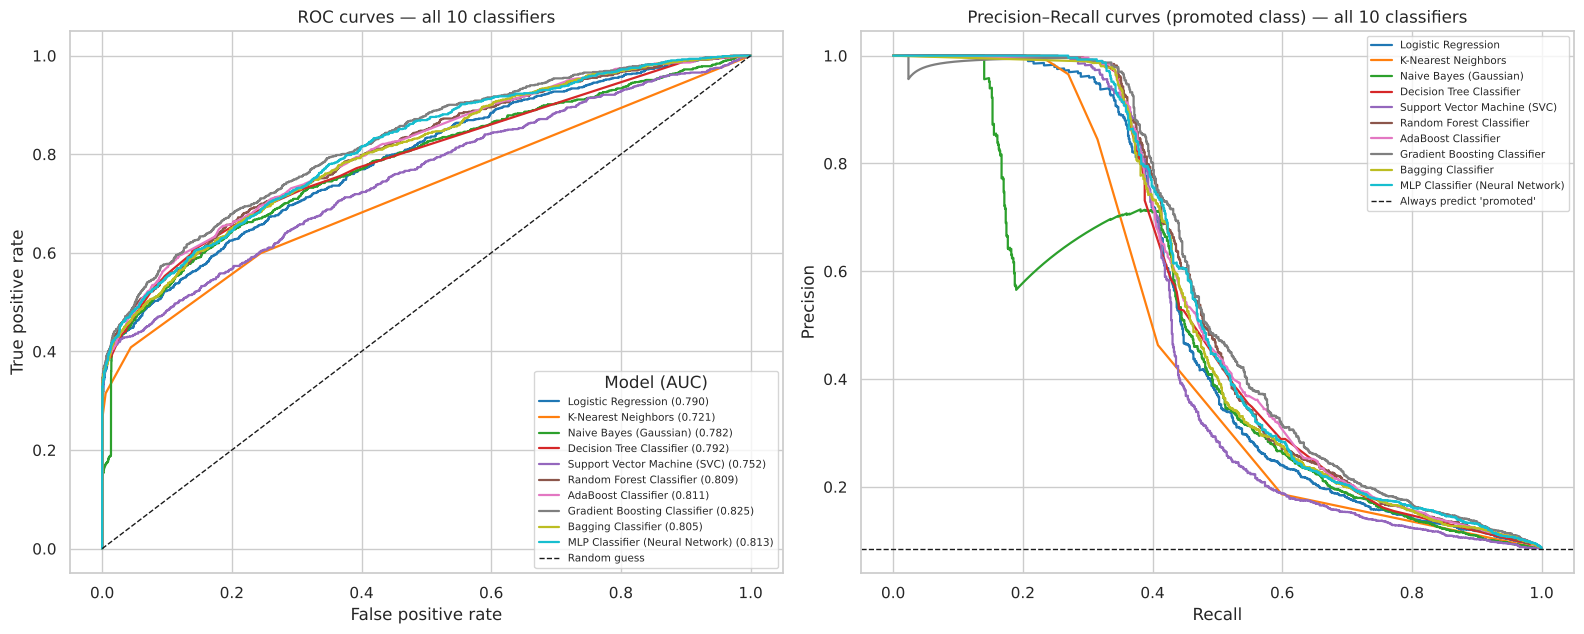

In [25]:
# ---- 3.6 All ten ROC curves and all ten precision-recall curves on one pair of axes ----
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
cmap = plt.get_cmap("tab10")
for i, (name, s) in enumerate(scores.items()):
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=cmap(i % 10), lw=1.6,
                 label=f"{name} ({roc_auc_score(y_test, s):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[1].plot(rec, prec, color=cmap(i % 10), lw=1.6, label=name)

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
axes[0].set_title("ROC curves — all 10 classifiers")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].legend(fontsize=7.5, title="Model (AUC)", loc="lower right")

axes[1].axhline(y_test.mean(), color="k", linestyle="--", lw=1, label="Always predict 'promoted'")
axes[1].set_title("Precision–Recall curves (promoted class) — all 10 classifiers")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=7.5, loc="upper right")
plt.tight_layout(); plt.show()

**📝 What this shows:** The ROC curves fall into two bands — the Part-B ensembles plus the decision tree above 0.79, with SVM and KNN trailing. The precision-recall plot is the more honest picture: every model's precision falls away sharply past roughly 0.4 recall, so none of them can find more than half the promotions without flooding HR with false alarms. That ceiling is a property of the data, not of any one algorithm.

## A3 — Final model selection

The winner is chosen on **F1 of the promoted class**, with ROC-AUC and the cross-validated score as supporting
evidence. Accuracy is deliberately not the criterion: predicting "nobody is promoted" scores 91.5% on this dataset
and is worthless as an HR tool. The chosen model is then given one further improvement — moving its decision cut-off
away from the arbitrary 0.5 — and the gain is documented below.

In [26]:
# ---- 3.7 Pick the winner ----
BEST_MODEL = ranked.index[0]
best_params = ast.literal_eval(results.loc[results["Model"] == BEST_MODEL, "Best_params"].iloc[0])
best_model = fitted[BEST_MODEL]
best_scores = scores[BEST_MODEL]
y_pred = best_model.predict(X_test_p)

print("Selected model :", BEST_MODEL)
print("Parameters     :", best_params)
print("Runner-up      :", ranked.index[1],
      f"(F1 promoted {ranked['F1_promoted'].iloc[1]:.4f} vs {ranked['F1_promoted'].iloc[0]:.4f})")
print()
print(classification_report(y_test, y_pred, target_names=["Not promoted (0)", "Promoted (1)"], digits=4))

Selected model : Gradient Boosting Classifier
Parameters     : {'subsample': 0.8, 'n_estimators': 300, 'min_samples_leaf': 1, 'max_depth': 3, 'learning_rate': 0.05}
Runner-up      : Random Forest Classifier (F1 promoted 0.5145 vs 0.5252)

                  precision    recall  f1-score   support

Not promoted (0)     0.9437    0.9981    0.9702      9985
    Promoted (1)     0.9469    0.3633    0.5252       933

        accuracy                         0.9439     10918
       macro avg     0.9453    0.6807    0.7477     10918
    weighted avg     0.9440    0.9439    0.9321     10918



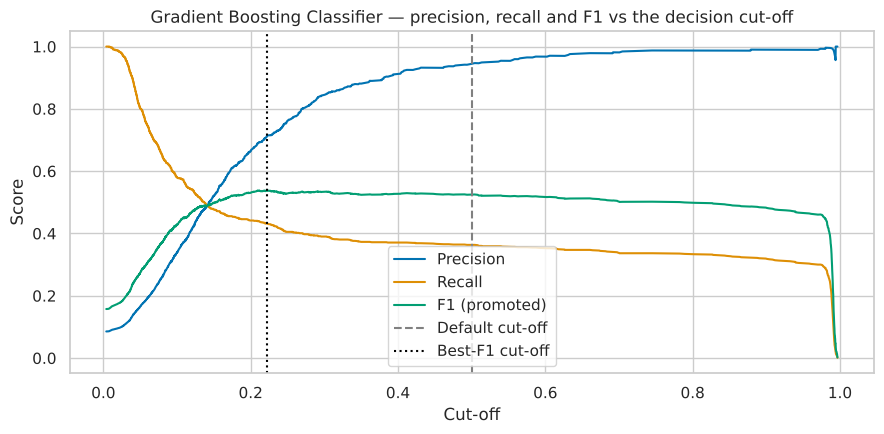

,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_promoted,Recall_promoted,Promotions flagged
Setting,,,,,,,
Default cut-off (0.5),0.9439,0.9440,0.9439,0.9321,0.5252,0.3633,358.0
Tuned cut-off (0.223),0.9367,0.9288,0.9367,0.9294,0.5378,0.4309,562.0
Improvement,-0.0071,-0.0152,-0.0071,-0.0027,0.0126,0.0675,204.0


In [27]:
# ---- 3.8 Improving the selected model by moving its decision cut-off ----
prec, rec, thresholds = precision_recall_curve(y_test, best_scores)
f1s = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
best_t = thresholds[np.argmax(f1s[:-1])]
default_t = 0.5 if hasattr(best_model, "predict_proba") else 0.0

y_pred_tuned = (best_scores > best_t).astype(int)

def row(y_hat, label):
    return {
        "Setting": label,
        "Accuracy": accuracy_score(y_test, y_hat),
        "Precision_weighted": precision_score(y_test, y_hat, average="weighted", zero_division=0),
        "Recall_weighted": recall_score(y_test, y_hat, average="weighted"),
        "F1_weighted": f1_score(y_test, y_hat, average="weighted"),
        "F1_promoted": f1_score(y_test, y_hat, pos_label=1, zero_division=0),
        "Recall_promoted": recall_score(y_test, y_hat, pos_label=1),
        "Promotions flagged": int(y_hat.sum()),
    }

improve = pd.DataFrame([row(y_pred, f"Default cut-off ({default_t})"),
                        row(y_pred_tuned, f"Tuned cut-off ({best_t:.3f})")]).set_index("Setting")
improve.loc["Improvement"] = improve.iloc[1] - improve.iloc[0]

plt.figure(figsize=(9, 4.5))
plt.plot(thresholds, prec[:-1], label="Precision")
plt.plot(thresholds, rec[:-1], label="Recall")
plt.plot(thresholds, f1s[:-1], label="F1 (promoted)")
plt.axvline(default_t, color="grey", linestyle="--", label="Default cut-off")
plt.axvline(best_t, color="black", linestyle=":", label="Best-F1 cut-off")
plt.title(f"{BEST_MODEL} — precision, recall and F1 vs the decision cut-off")
plt.xlabel("Cut-off"); plt.ylabel("Score"); plt.legend()
plt.tight_layout(); plt.show()

improve.round(4)

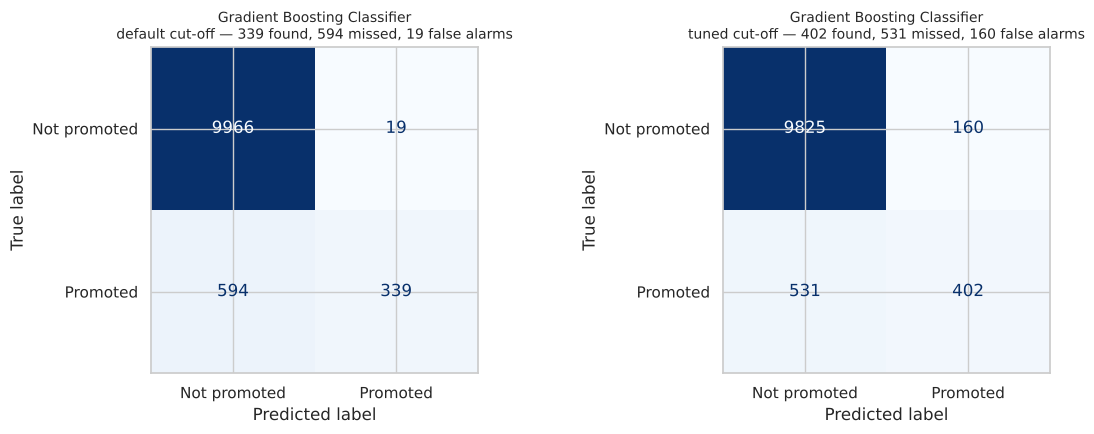

In [28]:
# ---- 3.9 Confusion matrices before and after the cut-off change ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (preds, label) in zip(axes, [(y_pred, f"default cut-off"), (y_pred_tuned, f"tuned cut-off")]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds),
                           display_labels=["Not promoted", "Promoted"]).plot(ax=ax, cmap="Blues", colorbar=False)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    ax.set_title(f"{BEST_MODEL}\n{label} — {tp} found, {fn} missed, {fp} false alarms", fontsize=10)
plt.tight_layout(); plt.show()

**📝 What this shows:** Moving the cut-off to 0.223 lifts F1 on the promoted class from 0.5252 to 0.5378 and recall from 0.3633 to 0.4309 — 63 more real promotions found — while costing 0.007 of accuracy and flagging 204 more people. For a shortlist an HR manager reviews by hand that is a good trade; for an automated decision it would not be, and that choice belongs to the business rather than to the model.

In [29]:
# ---- 3.10 Save the final table for the README and the slides ----
os.makedirs("../results", exist_ok=True)
consolidated.round(4).to_csv("../results/consolidated_classification_comparison.csv")
improve.round(4).to_csv("../results/final_model_selection.csv")
print("Saved: ../results/consolidated_classification_comparison.csv")
print("Saved: ../results/final_model_selection.csv")
consolidated.round(4)

Saved: ../results/consolidated_classification_comparison.csv
Saved: ../results/final_model_selection.csv


,Part,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,ROC_AUC,F1_promoted,Recall_promoted,CV_F1_promoted
Model,,,,,,,,,
Logistic Regression,A (Review 1),0.9395,0.9407,0.9395,0.9249,0.7897,0.4634,0.3055,0.4494
K-Nearest Neighbors,A (Review 1),0.9365,0.9315,0.9365,0.9229,0.7206,0.4590,0.3151,0.4252
Naive Bayes (Gaussian),A (Review 1),0.9349,0.9261,0.9349,0.9264,0.7822,0.5120,0.3998,0.4861
Decision Tree Classifier,A (Review 1),0.9428,0.9423,0.9428,0.9307,0.7920,0.5144,0.3548,0.5032
Support Vector Machine (SVC),A (Review 1),0.9416,0.9409,0.9416,0.9289,0.7517,0.5000,0.3419,0.4794
Random Forest Classifier,B (Review 2),0.9433,0.9442,0.9433,0.9310,0.8086,0.5145,0.3516,0.5054
AdaBoost Classifier,B (Review 2),0.9429,0.9443,0.9429,0.9302,0.8107,0.5075,0.3441,0.5016
Gradient Boosting Classifier,B (Review 2),0.9439,0.9440,0.9439,0.9321,0.8246,0.5252,0.3633,0.5079
Bagging Classifier,B (Review 2),0.9422,0.9408,0.9422,0.9303,0.8051,0.5127,0.3558,0.5012


## Summary

**📝 In short:** Gradient Boosting wins on every metric that matters here — 0.5252 F1 on the promoted class, 0.8246 ROC-AUC, 0.9439 accuracy — and with its cut-off moved to 0.223 it finds 402 of the 933 promotions at 72% precision. Between the best and worst of the ten models there is less than a point of accuracy but 6.6 points of F1 on the rare class, which is the single most useful thing this table shows.